# Function Approximation with Neural Networks

A neural network is a universal function approximator. Here small Keras networks learn:

1. a **physics equation** `s = u*t + 1/2*a*t^2`
2. a **quadratic** `y = x^2 - 3x + 2`
3. a **straight line** `y = 2x + 3`

Each is trained with the Adam optimiser on the MSE loss, then compared with the true curve.

In [ ]:
# Libraries: NumPy and Matplotlib for data/plots, Keras (via TensorFlow) for the neural network.
import numpy as np 
import matplotlib.pyplot as plt 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


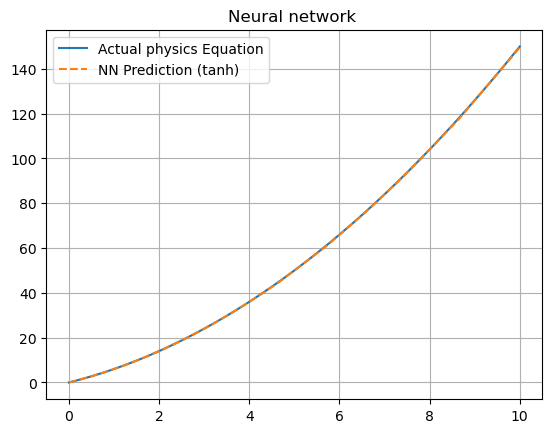

In [ ]:
# Learn the displacement equation s = u*t + 0.5*a*t^2.
# NOTE: an inline comment mentions TANH, but the layers actually use ReLU.
# initial velocity u and acceleration a
u= 5
a = 2 
# 200 time points between 0 and 10
t = np.linspace(0,10,200)
# true displacement from the physics equation (the training target)
s = u*t + 0.5*a*(t**2)

# reshape
# Keras expects 2-D inputs: (samples, features)
t_train = t.reshape(-1,1)
s_train = s.reshape(-1,1)


# Neural network with TANH activation
model = Sequential([
    # hidden layer 1: 40 ReLU units (input has 1 feature)
    Dense(40,activation='relu',input_shape=(1,)),
    Dense(40,activation='relu'),
    # output layer: 1 linear unit for regression
    Dense(1)
])

# compile
model.compile(optimizer='adam',loss='mse')

# train
model.fit(t_train,s_train,epochs=2000,verbose=0)

# predict
s_pred = model.predict(t_train)

# plot
# overlay the true curve and the network prediction
plt.plot(t,s,label="Actual physics Equation")
plt.plot(t,s_pred,'--',label="NN Prediction (tanh)")
plt.title("Neural network ")
plt.legend()
plt.grid(True)
plt.show()

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


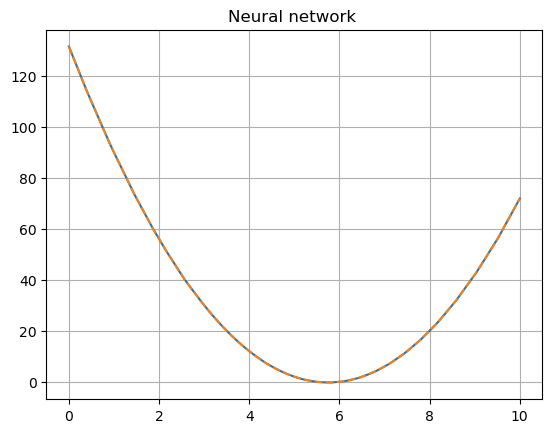

In [ ]:
# Fit the quadratic y = x^2 - 3x + 2.
# NOTE: this cell reuses `model` (and `t`, `s_pred`) from the previous cell instead of building a new network,
# so the plot shows the previous cell's predictions. Re-create the model here for a standalone run.
import numpy as np 
import matplotlib.pyplot as plt 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# quadratic coefficients
# quadratic coefficients
a,b,c=1,-3,2

# traning data
# training inputs from -10 to 10
x=np.linspace(-10,10,200)
y = a * x**2 + b * x +c 

# reshape for neural network
t_train = x.reshape(-1,1)
s_train = y.reshape(-1,1)
model.compile(optimizer='adam',loss='mse')

# train
model.fit(t_train,s_train,epochs=2000,verbose=0)

# predict
s_pred = model.predict(t_train)


# plot
plt.plot(t,s_pred)
plt.plot(t,s_pred,'--')
plt.title("Neural network ")

plt.grid(True)
plt.show()

In [ ]:
# # NOTE: stray text, not valid Python - it looks like a reminder to try fitting a wave (sinusoidal) function next.
# # Running this cell raises a SyntaxError.
# synersider wave 

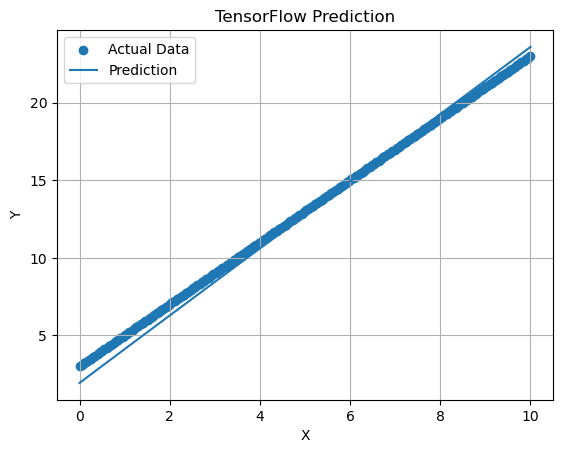

Model saved and loaded successfully!


In [ ]:
# Simplest example: learn y = 2x + 3 with a small network of two hidden layers.
# NOTE: the final print says the model was 'saved and loaded', but this notebook contains no save/load code.
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

# 1. Create data
x = np.linspace(0, 10, 200)
y = 2*x + 3

# 2. Create model
model = Sequential([
    tf.keras.Input(shape=(1,)),
    Dense(16, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")

# 3. Train
model.fit(x, y, epochs=100, verbose=0)

# 4. Predict
y_pred = model.predict(x, verbose=0).flatten()

# 5. Plot
plt.scatter(x, y, label="Actual Data")
plt.plot(x, y_pred, label="Prediction")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("TensorFlow Prediction")
plt.legend()
plt.grid(True)
plt.show()

print("Model saved and loaded successfully!")